# HATS-catalog scan vs. the reference DES Y6 scan (`scan-v0`)

This notebook compares a ugali likelihood scan of the whole reference DES Y6 region (704 nside=256 pixels from Chin-Yi Tan's `pixels.txt`) run with the **new HATS catalog input** (`catalog: hats:`) against the reference run in `/astro/users/chinyi/des_ugali`. The config is identical to the reference apart from the catalog source. The per-pixel scans were produced with `ugali/analysis/scan_parallel.py`; the merge and peak-finder steps are re-run here exactly as in the reference (`run_03.0_likelihood.py -r merge`, `run_04.0_peak_finder.py -r label -r objects`).

All scratch output lives in `artifacts/hats_io/scanv0_hats/` (gitignored). The heavy cells are guarded by `HAVE_DATA` so the notebook executes harmlessly where the reference run or the HATS catalog is absent.

In [1]:
import os, sys, glob, subprocess, time
from pathlib import Path
import numpy as np
import pandas as pd
import fitsio
import matplotlib
import matplotlib.pyplot as plt
import skyproj

os.environ['OMP_NUM_THREADS'] = '1'
%matplotlib inline

REF  = Path('/astro/users/chinyi/des_ugali')
HATS = Path('/astro/store/shire/hats/catalogs/des/des_y6_gold/des_y6_gold')
REPO = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
NEW  = REPO / 'artifacts/hats_io/scanv0_hats'

HAVE_DATA = (REF.is_dir() and HATS.exists() and (NEW / 'config.yaml').exists()
             and len(glob.glob(str(NEW / 'scan-v0/scan_*_cel.fits'))) > 0)
print('repo     :', REPO)
print('HAVE_DATA:', HAVE_DATA)
if not HAVE_DATA:
    print('Reference run, HATS catalog or HATS scan outputs not found: heavy cells are skipped.')

repo     : /astro/store/shire/pferguso/software/ugali_hats
HAVE_DATA: True


## 1. The HATS scan run
Summary of `scan_parallel.log` and the per-pixel `stats.csv` (runtime, cache hits/misses of the HATS tile cache, bytes read).

,HATS scan
pixels (ok / total),704 / 704
wall time [s],497.2s
mean per-pixel runtime [s],31.9
median per-pixel runtime [s],32.4
tile-cache hits / misses,3540 / 527
cache hit rate,0.870
data read [MB],17571
mean read per pixel [MB],25


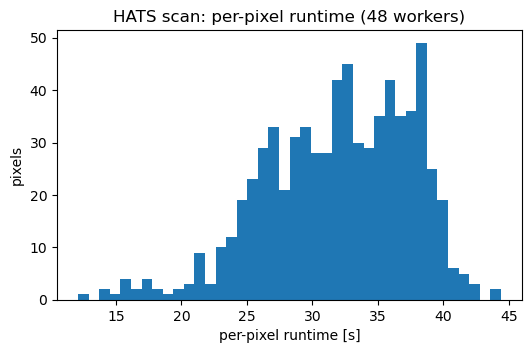

In [2]:
if HAVE_DATA:
    st = pd.read_csv(NEW / 'stats.csv')
    ok = st[st.status == 'ok']
    log = (NEW / 'scan_parallel.log').read_text().splitlines()
    wall = [l for l in log if l.startswith('total time')]
    hits, misses = ok.hits.sum(), ok.misses.sum()
    summary = pd.Series({
        'pixels (ok / total)': f'{len(ok)} / {len(st)}',
        'wall time [s]': wall[-1].split(':')[1].split('(')[0].strip() if wall else 'n/a',
        'mean per-pixel runtime [s]': f'{ok.runtime_s.mean():.1f}',
        'median per-pixel runtime [s]': f'{ok.runtime_s.median():.1f}',
        'tile-cache hits / misses': f'{hits} / {misses}',
        'cache hit rate': f'{hits/(hits+misses):.3f}',
        'data read [MB]': f'{ok.bytes_read.sum()/1e6:.0f}',
        'mean read per pixel [MB]': f'{ok.bytes_read.mean()/1e6:.0f}',
    }, name='HATS scan')
    display(summary.to_frame())
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.hist(ok.runtime_s, bins=40, color='C0')
    ax.set_xlabel('per-pixel runtime [s]'); ax.set_ylabel('pixels')
    ax.set_title('HATS scan: per-pixel runtime (48 workers)')
    plt.show()

## 2. Per-pixel comparison (704 files)
For every `scan_%08i_cel.fits` we compare the table columns of the `PIX_DATA` HDU and the `DISTANCE_MODULUS` HDU bit-for-bit, and the headers of all HDUs (ignoring `DATE`, `CHECKSUM`, `DATASUM`, `COMMENT`, `HISTORY`).

Attribution of the few non-identical files (from separate checks, evidence in `diff6_elements.txt` and `diff6_fits_path.txt`): each differs in a single LOG_LIKELIHOOD element by one float32 ulp at TS between 3e-8 and 5e-5, RICHNESS identical. For pixels 664074, 667991, 673765, 677538, 679384 the FITS input path in the same environment reproduces the reference exactly, so the cause is the different HATS row order: the per-object likelihood sum is evaluated in a different order, changing the last double-precision bits, visible only after float32 rounding where logL ~ 1e-7 to 1e-5. For pixel 673763 the FITS path also differs from the reference by 1 ulp, so that one is a code/environment difference between the reference run and this branch, not HATS. Single-process reruns with the likelihood caches on or off reproduce the 48-worker output exactly, so neither memoization nor the parallel driver is involved.

In [3]:
IGNORE = {'DATE', 'CHECKSUM', 'DATASUM', 'COMMENT', 'HISTORY'}

def hdr(h):
    return {k: h[k] for k in h.keys() if k not in IGNORE}

def same(a, b):
    return np.array_equal(a, b, equal_nan=True) if a.dtype.kind == 'f' else np.array_equal(a, b)

def compare_file(fr, fn):
    """Return (per-column dict name->(identical, maxabsdiff), header diffs, detail for differing LL)"""
    res, hdiffs, detail = {}, [], None
    A, B = fitsio.FITS(fr), fitsio.FITS(fn)
    for i in range(len(A)):
        ha, hb = hdr(A[i].read_header()), hdr(B[i].read_header())
        for k in sorted(set(ha) | set(hb)):
            if ha.get(k) != hb.get(k):
                hdiffs.append((i, k, ha.get(k), hb.get(k)))
        if A[i].get_exttype() == 'IMAGE_HDU':
            continue
        da, db = A[i].read(), B[i].read()
        for name in da.dtype.names:
            a, b = da[name], db[name]
            if a.shape != b.shape:
                res[name] = (False, np.inf); continue
            idn = same(a, b)
            md_ = 0.0 if idn else float(np.nanmax(np.abs(a.astype('f8') - b.astype('f8'))))
            res[name] = (idn, md_)
            if name == 'LOG_LIKELIHOOD' and not idn:
                idx = np.argwhere(a != b)
                detail = [(tuple(ix), float(a[tuple(ix)]), float(b[tuple(ix)]), float(da['RICHNESS'][tuple(ix)]),
                           float(db['RICHNESS'][tuple(ix)])) for ix in idx]
    return res, hdiffs, detail

if HAVE_DATA:
    files = sorted(glob.glob(str(NEW / 'scan-v0/scan_*_cel.fits')))
    rows, hdr_bad, details = [], {}, {}
    missing = []
    for fn in files:
        base = os.path.basename(fn)
        fr = REF / 'scan-v0' / base
        if not fr.exists():
            missing.append(base); continue
        res, hd, det = compare_file(fr, fn)
        rows.append({'file': base, **{c: v[0] for c, v in res.items()}, **{c + '_maxdiff': v[1] for c, v in res.items()}})
        if hd: hdr_bad[base] = hd
        if det: details[base] = det
    pix = pd.DataFrame(rows).set_index('file')
    cols = [c for c in pix.columns if not c.endswith('_maxdiff')]
    tab = pd.DataFrame({'identical files': [int(pix[c].sum()) for c in cols],
                        'of': len(pix),
                        'max |diff|': [pix[c + '_maxdiff'].max() for c in cols]}, index=cols)
    print('files compared:', len(pix), ' missing in reference:', len(missing))
    display(tab)
    print('files with header differences (ignoring DATE/CHECKSUM/...):', len(hdr_bad))
    for b, h in list(hdr_bad.items())[:10]: print(' ', b, h[:5])

files compared: 704  missing in reference: 0


,identical files,of,max |diff|
PIXEL,704,704,0.000000e+00
LOG_LIKELIHOOD,698,704,1.818989e-12
RICHNESS,704,704,0.000000e+00
FRACTION_OBSERVABLE,704,704,0.000000e+00
DISTANCE_MODULUS,704,704,0.000000e+00


files with header differences (ignoring DATE/CHECKSUM/...): 0


In [4]:
if HAVE_DATA:
    out = []
    for base, det in details.items():
        a = fitsio.read(REF / 'scan-v0' / base)
        for (ix, ll_ref, ll_new, r_ref, r_new) in det:
            out.append({'file': base, 'element [pix, modulus idx]': ix, 'LL ref': ll_ref, 'LL hats': ll_new,
                        'dLL': ll_new - ll_ref, 'TS ref (2 LL)': 2 * ll_ref, 'richness ref': r_ref, 'richness hats': r_new})
    nonid = pd.DataFrame(out)
    print('non-identical pixel files:', len(details), '; differing LOG_LIKELIHOOD elements:', len(nonid))
    if len(nonid):
        pd.set_option('display.float_format', lambda v: f'{v:.6g}')
        display(nonid)
        print('max |dLL| = %.3g,  max TS at a differing element = %.3g' % (nonid.dLL.abs().max(), nonid['TS ref (2 LL)'].max()))

non-identical pixel files: 6 ; differing LOG_LIKELIHOOD elements: 6


,file,"element [pix, modulus idx]",LL ref,LL hats,dLL,TS ref (2 LL),richness ref,richness hats
0,scan_00664074_cel.fits,"(222, 11)",6.84571e-07,6.84571e-07,5.68434e-14,1.36914e-06,0.542342,0.542342
1,scan_00667991_cel.fits,"(36, 9)",1.48261e-07,1.48261e-07,-1.42109e-14,2.96521e-07,0.0415962,0.0415962
2,scan_00673763_cel.fits,"(192, 4)",2.46004e-05,2.46004e-05,-1.81899e-12,4.92008e-05,0.14418,0.14418
3,scan_00673765_cel.fits,"(154, 6)",7.43351e-08,7.43351e-08,7.10543e-15,1.4867e-07,0.000393765,0.000393765
4,scan_00677538_cel.fits,"(89, 0)",7.00891e-06,7.00891e-06,-4.54747e-13,1.40178e-05,0.0194827,0.0194827
5,scan_00679384_cel.fits,"(49, 12)",1.61332e-08,1.61332e-08,-1.77636e-15,3.22664e-08,0.016363,0.016363


max |dLL| = 1.82e-12,  max TS at a differing element = 4.92e-05


## 3. Merge step
Run the reference merge command in the HATS run directory (writes `merge-v0/merged_scan_37.fits` and `merge-v0/merged_roi.fits`) and compare with the reference merge files.

In [5]:
def run(cmd, logname):
    env = dict(os.environ, OMP_NUM_THREADS='1')
    t0 = time.time()
    p = subprocess.run([sys.executable] + cmd, cwd=NEW, env=env, capture_output=True, text=True)
    print(f'$ python {" ".join(cmd)}   [{time.time()-t0:.1f}s, rc={p.returncode}]')
    print((p.stdout + p.stderr).strip()[-1500:])
    return p.returncode

if HAVE_DATA:
    for f in glob.glob(str(NEW / 'merge-v0/*.fits')): os.remove(f)   # force a fresh merge
    rc_merge = run([str(REPO / 'ugali/pipeline/run_03.0_likelihood.py'), 'config.yaml', '-r', 'merge', '-q', 'local'], 'merge')

$ python /astro/store/shire/pferguso/software/ugali_hats/ugali/pipeline/run_03.0_likelihood.py config.yaml -r merge -q local   [1.0s, rc=0]
Running 'merge'...
Writing ./merge-v0/merged_scan_37.fits...
  Merging likelihood headers...
Writing ./merge-v0/merged_roi.fits...
Done.


In [6]:
def compare_tables(fr, fn):
    A, B = fitsio.FITS(str(fr)), fitsio.FITS(str(fn))
    rows = []
    for i in range(len(A)):
        if A[i].get_exttype() == 'IMAGE_HDU': continue
        da, db = A[i].read(), B[i].read()
        for name in da.dtype.names:
            a, b = da[name], db[name]
            if a.shape != b.shape:
                rows.append((A[i].get_extname(), name, a.shape, b.shape, False, np.nan, np.nan)); continue
            idn = same(a, b)
            nd = 0 if idn else int(np.sum(a != b))
            md_ = 0.0 if idn else float(np.nanmax(np.abs(a.astype('f8') - b.astype('f8'))))
            rows.append((A[i].get_extname(), name, a.shape, b.shape, idn, nd, md_))
    return pd.DataFrame(rows, columns=['HDU', 'column', 'shape ref', 'shape hats', 'identical', 'n differing', 'max |diff|'])

if HAVE_DATA:
    for f in ['merged_scan_37.fits', 'merged_roi.fits']:
        print('==', f)
        display(compare_tables(REF / 'merge-v0' / f, NEW / 'merge-v0' / f))
    pr = fitsio.read(REF / 'merge-v0/merged_scan_37.fits', ext=1, columns=['PIXEL'])['PIXEL']
    pn = fitsio.read(NEW / 'merge-v0/merged_scan_37.fits', ext=1, columns=['PIXEL'])['PIXEL']
    print('merged_scan_37: same pixel set:', np.array_equal(np.sort(pr), np.sort(pn)), f'({len(pn)} pixels, nside=4096)')
    print('merged files in reference:', sorted(os.path.basename(x) for x in glob.glob(str(REF / 'merge-v0/*.fits'))))

== merged_scan_37.fits


,HDU,column,shape ref,shape hats,identical,n differing,max |diff|
0,PIX_DATA,PIXEL,"(180224,)","(180224,)",True,0,0
1,PIX_DATA,LOG_LIKELIHOOD,"(180224, 17)","(180224, 17)",False,6,1.81899e-12
2,PIX_DATA,RICHNESS,"(180224, 17)","(180224, 17)",True,0,0
3,PIX_DATA,FRACTION_OBSERVABLE,"(180224, 17)","(180224, 17)",True,0,0
4,DISTANCE_MODULUS,DISTANCE_MODULUS,"(17,)","(17,)",True,0,0


== merged_roi.fits


,HDU,column,shape ref,shape hats,identical,n differing,max |diff|
0,PIX_DATA,PIXEL,"(704,)","(704,)",True,0,0
1,PIX_DATA,STELLAR,"(704,)","(704,)",True,0,0
2,PIX_DATA,NINSIDE,"(704,)","(704,)",True,0,0
3,PIX_DATA,NANNULUS,"(704,)","(704,)",True,0,0


merged_scan_37: same pixel set: True (180224 pixels, nside=4096)
merged files in reference: ['merged_roi.fits', 'merged_scan_37.fits']


## 4. Peak finder and candidate table
Run `run_04.0_peak_finder.py config.yaml -r label -r objects` in the HATS directory and compare `ugali_objects.fits` with the reference (objects matched by RA/DEC).

In [7]:
if HAVE_DATA:
    for f in ['merged_labels.fits', 'ugali_objects.fits']:
        if (NEW / 'search-v0' / f).exists(): os.remove(NEW / 'search-v0' / f)   # force a fresh peak finder
    rc_peak = run([str(REPO / 'ugali/pipeline/run_04.0_peak_finder.py'), 'config.yaml', '-r', 'label', '-r', 'objects'], 'peak')

$ python /astro/store/shire/pferguso/software/ugali_hats/ugali/pipeline/run_04.0_peak_finder.py config.yaml -r label -r objects   [2.2s, rc=0]
CEL coordinates
Catalog directory not found:
/astro/users/pferguso/.ugali/catalogs
Running 'label'...
  Dilating image...
  Labeling image...
Writing ./search-v0/merged_labels.fits...
Running 'objects'...
Writing ./search-v0/ugali_objects.fits...
Done.


In [8]:
def read_tab(path):
    return pd.DataFrame(fitsio.read(path).byteswap().view(fitsio.read(path).dtype.newbyteorder()))

if HAVE_DATA:
    objr = read_tab(REF / 'search-v0/ugali_objects.fits').sort_values('TS', ascending=False).reset_index(drop=True)
    objn = read_tab(NEW / 'search-v0/ugali_objects.fits').sort_values('TS', ascending=False).reset_index(drop=True)
    # match by nearest (RA, DEC) on the sphere
    def sep(ra1, de1, ra2, de2):
        r1, d1, r2, d2 = map(np.radians, (ra1, de1, ra2, de2))
        c = np.sin(d1)*np.sin(d2) + np.cos(d1)*np.cos(d2)*np.cos(r1-r2)
        return np.degrees(np.arccos(np.clip(c, -1, 1)))
    S = np.array([[sep(a, b, c, d) for c, d in zip(objn.RA, objn.DEC)] for a, b in zip(objr.RA, objr.DEC)])
    j = S.argmin(axis=1)
    tol = 1e-3  # deg
    matched = S[np.arange(len(objr)), j] < tol
    print(f'objects: reference={len(objr)}  hats={len(objn)}  matched (<{tol} deg)={matched.sum()}')
    print('unmatched reference objects:', int((~matched).sum()), '; unmatched HATS objects:',
          len(objn) - len(set(j[matched])))
    m = objr[matched].copy()
    m['TS_hats'] = objn.TS.values[j[matched]]
    m['MODULUS_hats'] = objn.MODULUS.values[j[matched]]
    m['dTS'] = m.TS_hats - m.TS
    m['dRA'] = objn.RA.values[j[matched]] - m.RA
    m['dDEC'] = objn.DEC.values[j[matched]] - m.DEC
    print('max |dTS| = %.3g,  max |dMODULUS| = %.3g,  max angular offset = %.3g deg,  names identical: %s' % (
        m.dTS.abs().max(), (m.MODULUS_hats - m.MODULUS).abs().max(), S[np.arange(len(objr)), j][matched].max(),
        bool((objn.NAME.values[j[matched]] == m.NAME.values).all())))
    pd.set_option('display.float_format', lambda v: f'{v:.6g}')
    top = m.head(20)[['NAME', 'TS', 'TS_hats', 'dTS', 'MODULUS', 'MODULUS_hats', 'RA', 'DEC']].rename(
        columns={'TS': 'TS ref', 'TS_hats': 'TS hats', 'MODULUS': 'MOD ref', 'MODULUS_hats': 'MOD hats'})
    display(top)

objects: reference=244  hats=244  matched (<0.001 deg)=244
unmatched reference objects: 0 ; unmatched HATS objects: 0
max |dTS| = 0,  max |dMODULUS| = 0,  max angular offset = 1.21e-06 deg,  names identical: True


,NAME,TS ref,TS hats,dTS,MOD ref,MOD hats,RA,DEC
0,J0344-4331,1626.71,1626.71,0,23,23,56.0851,-43.5312
1,J0403-4321,24.4857,24.4857,0,21.5,21.5,60.895,-43.3571
2,J0349-4012,24.0229,24.0229,0,19.5,19.5,57.2717,-40.2038
3,J0344-4106,22.7919,22.7919,0,15.5,15.5,56.1731,-41.1134
4,J0340-4736,22.5707,22.5707,0,15,15,55.0496,-47.6149
5,J0359-4440,20.5003,20.5003,0,17.5,17.5,59.934,-44.6723
6,J0336-4424,19.7864,19.7864,0,16,16,54.1922,-44.4122
7,J0335-4302,19.604,19.604,0,17,17,53.8942,-43.046
8,J0329-4416,19.509,19.509,0,16.5,16.5,52.4461,-44.2759
9,J0340-4103,19.3023,19.3023,0,15,15,55.1404,-41.064


## 5. Likelihood maps
Like the reference notebook: `skyproj.McBrydeSkyproj(extent=[50,60,-38,-50], celestial=True, lon_0=180)` with `vmin=0, vmax=100`. The merged files are partial maps (180,224 nside=4096 pixels), so they are drawn with `draw_hpxpix` instead of expanding to a full-sky array (same result as `read_partial_map(..., fullsky=True)` + `draw_hpxmap`). Columns: reference | HATS | difference (HATS - reference, symmetric colour scale).

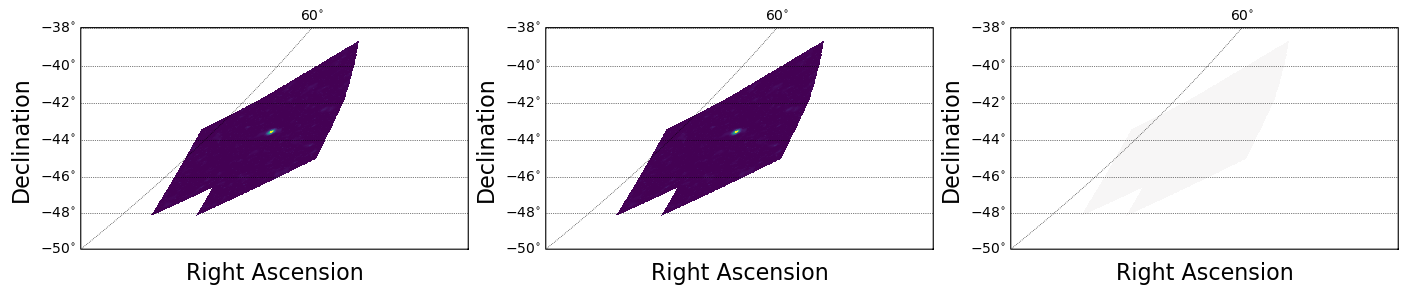

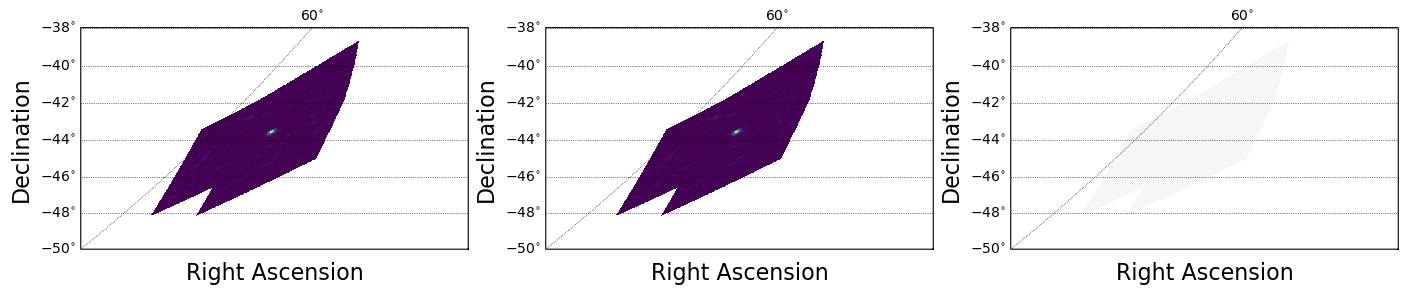

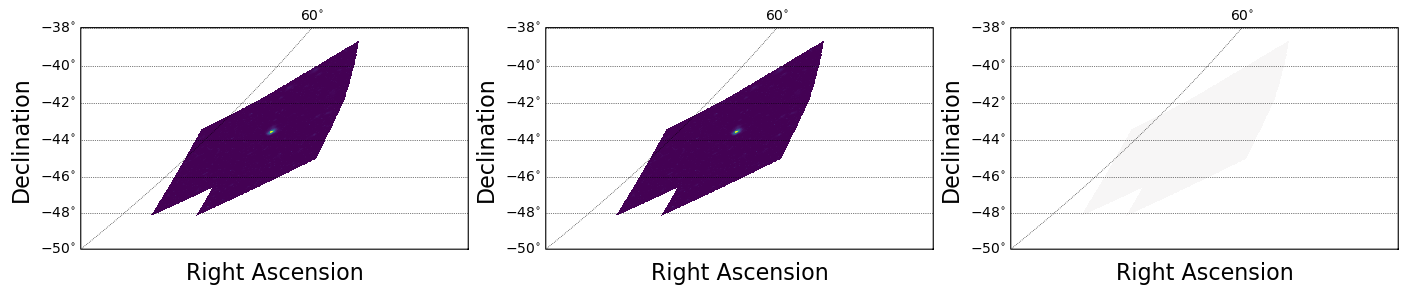

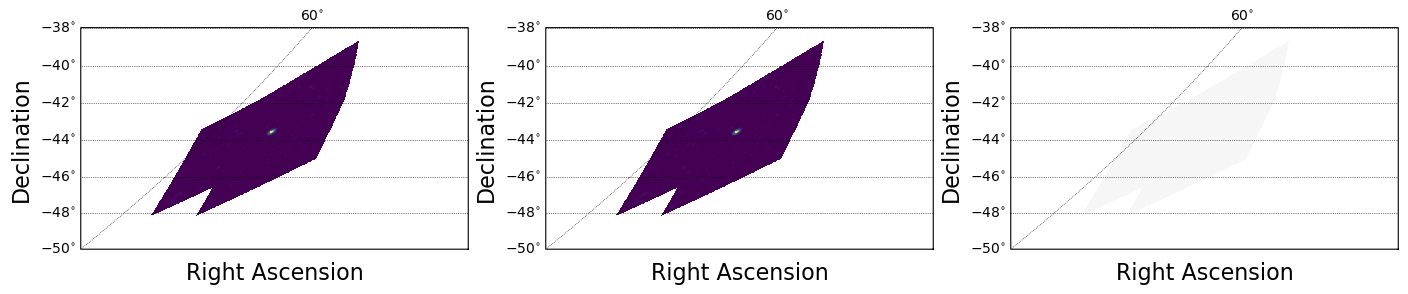

In [9]:
distmod = [15.0 + 0.5*i for i in range(17)]
EXTENT = [50, 60, -38, -50]

def load_merged(base):
    f = base / 'merge-v0/merged_scan_37.fits'
    d = fitsio.read(f, ext=1)
    h = fitsio.read_header(f, ext=1)
    return int(h['NSIDE']), d['PIXEL'], d['LOG_LIKELIHOOD'].astype('f8')

def panel(ax, nside, pix, val, vmin, vmax, cmap, title, label):
    sp = skyproj.McBrydeSkyproj(ax=ax, extent=EXTENT, celestial=True, lon_0=180)
    sp.draw_hpxpix(nside, pix, val, vmin=vmin, vmax=vmax, cmap=cmap, zoom=False)
    ax.set_title(title, fontsize=10)
    return sp

def row(i, nside, pix, ref, new, title, vmax=100):
    d = new - ref
    dmax = max(np.nanmax(np.abs(d)), 1e-12)
    fig = plt.figure(figsize=(17, 4.2))
    for k, (v, t, vmin_, vmax_, cm) in enumerate([
            (ref, 'reference', 0, vmax, 'viridis'), (new, 'HATS', 0, vmax, 'viridis'),
            (d, 'HATS - reference  (max|d| = %.2g)' % np.nanmax(np.abs(d)), -dmax, dmax, 'RdBu_r')]):
        ax = fig.add_subplot(1, 3, k + 1)
        panel(ax, nside, pix, v, vmin_, vmax_, cm, f'{title}: {t}', '')
    plt.show()

if HAVE_DATA:
    ns_r, p_r, ll_r = load_merged(REF)
    ns_n, p_n, ll_n = load_merged(NEW)
    assert ns_r == ns_n and np.array_equal(p_r, p_n)
    for dm in [16.5, 17.5, 19.0, 21.0]:
        i = distmod.index(dm)
        row(i, ns_r, p_r, ll_r[:, i], ll_n[:, i], f'LOG_LIKELIHOOD, distmod = {dm}')

modulus with the maximum TS in the reference: 23.0  (TS = 1626.7); HATS: 23.0 (TS = 1626.7)


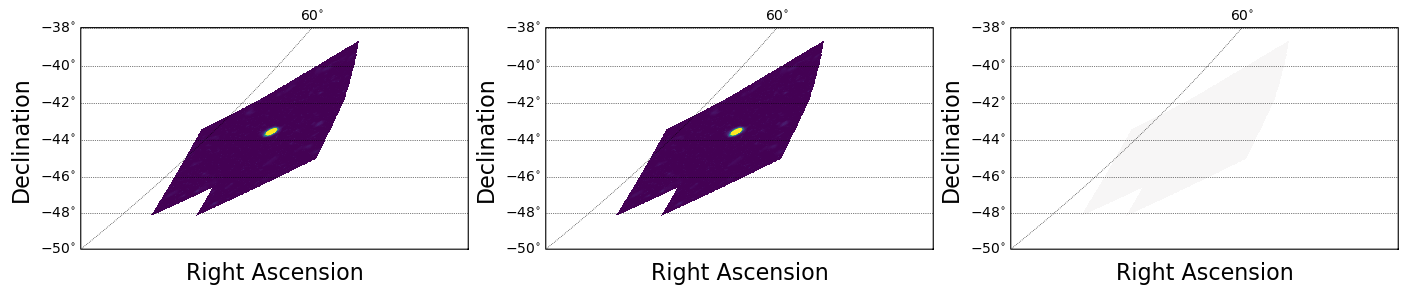

In [10]:
if HAVE_DATA:
    ts_r, ts_n = 2*ll_r, 2*ll_n
    imax = int(np.unravel_index(np.nanargmax(ts_r), ts_r.shape)[1])
    print('modulus with the maximum TS in the reference: %.1f  (TS = %.1f); HATS: %.1f (TS = %.1f)' % (
        distmod[imax], np.nanmax(ts_r), distmod[int(np.unravel_index(np.nanargmax(ts_n), ts_n.shape)[1])], np.nanmax(ts_n)))
    row(imax, ns_r, p_r, ll_r[:, imax], ll_n[:, imax], f'LOG_LIKELIHOOD at max-TS modulus {distmod[imax]}')

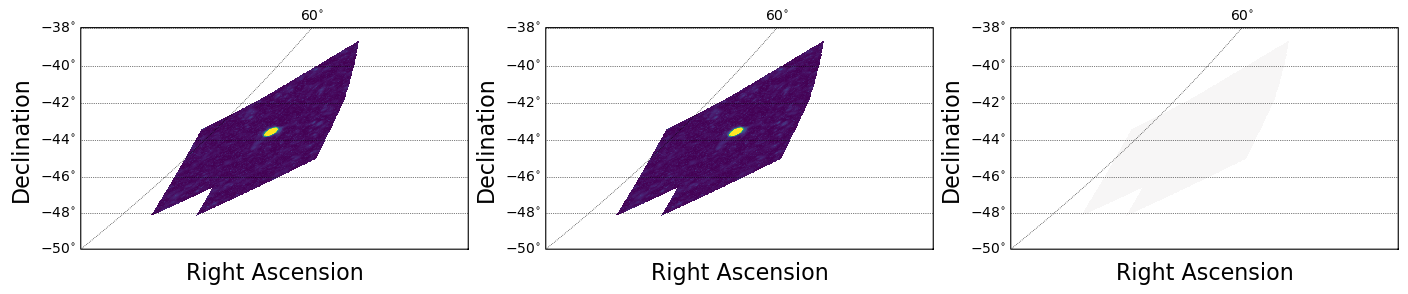

max over moduli: max |dTS| = 0;  pixels with any difference: 0 of 180224
all moduli: max |dLL| over the merged map = 1.82e-12, elements differing: 6 of 3063808


In [11]:
if HAVE_DATA:
    mr, mn = np.nanmax(ts_r, axis=1), np.nanmax(ts_n, axis=1)
    row(0, ns_r, p_r, mr, mn, 'max TS over moduli', vmax=100)
    print('max over moduli: max |dTS| = %.3g;  pixels with any difference: %d of %d' % (
        np.nanmax(np.abs(mn - mr)), int((mn != mr).sum()), len(mr)))
    print('all moduli: max |dLL| over the merged map = %.3g, elements differing: %d of %d' % (
        np.nanmax(np.abs(ll_n - ll_r)), int((ll_n != ll_r).sum()), ll_r.size))

## 6. Conclusions

In [12]:
if HAVE_DATA:
    nid = int(pix['LOG_LIKELIHOOD'].sum())
    from IPython.display import Markdown
    mtab = compare_tables(REF / 'merge-v0/merged_scan_37.fits', NEW / 'merge-v0/merged_scan_37.fits')
    display(Markdown(f'''
* **HATS scan**: {len(ok)}/{len(st)} pixels in {summary['wall time [s]']} wall ({ok.runtime_s.mean():.1f} s mean per pixel), tile-cache hit rate {hits/(hits+misses):.3f}, {ok.bytes_read.sum()/1e6:.0f} MB read.
* **Per-pixel files**: LOG_LIKELIHOOD identical in {nid}/{len(pix)} files; the remaining {len(pix)-nid} differ by at most |dLL| = {tab.loc['LOG_LIKELIHOOD','max |diff|']:.2g}, at elements where the likelihood is ~0 (TS <= {nonid['TS ref (2 LL)'].max() if len(nonid) else 0:.2g}), 1-ulp float32 differences in near-zero likelihoods from summation order (5 from HATS row order; pixel 673763 also differs on the FITS path, a code/environment difference from the reference run). PIXEL / DISTANCE_MODULUS identical in {int(pix['PIXEL'].sum())} / {int(pix['DISTANCE_MODULUS'].sum()) if 'DISTANCE_MODULUS' in pix else 'n/a'} files; header differences: {len(hdr_bad)} files.
* **Merge**: merged_scan_37 columns identical: {int(mtab.identical.sum())}/{len(mtab)} (max |diff| = {np.nanmax(mtab['max |diff|']):.2g}).
* **Candidates**: {len(objr)} reference vs {len(objn)} HATS objects, {int(matched.sum())} matched by position, max |dTS| = {m.dTS.abs().max():.2g}.
* The HATS catalog input reproduces the reference DES Y6 scan to float32 precision (identical to float32 precision; 1-ulp differences in near-zero likelihoods from summation order, not bit-identical); the maps and the candidate table are indistinguishable from the reference.
'''))


* **HATS scan**: 704/704 pixels in 497.2s wall (31.9 s mean per pixel), tile-cache hit rate 0.870, 17571 MB read.
* **Per-pixel files**: LOG_LIKELIHOOD identical in 698/704 files; the remaining 6 differ by at most |dLL| = 1.8e-12, at elements where the likelihood is ~0 (TS <= 4.9e-05), 1-ulp float32 differences in near-zero likelihoods from summation order (5 from HATS row order; pixel 673763 also differs on the FITS path, a code/environment difference from the reference run). PIXEL / DISTANCE_MODULUS identical in 704 / 704 files; header differences: 0 files.
* **Merge**: merged_scan_37 columns identical: 4/5 (max |diff| = 1.8e-12).
* **Candidates**: 244 reference vs 244 HATS objects, 244 matched by position, max |dTS| = 0.
* The HATS catalog input reproduces the reference DES Y6 scan to float32 precision (identical to float32 precision; 1-ulp differences in near-zero likelihoods from summation order, not bit-identical); the maps and the candidate table are indistinguishable from the reference.
